# 06 — Edge-IIoTset Ensemble Feasibility

**Goal:** Check whether adding models improves the **same frozen validation records**, and whether the extra resource cost is worthwhile.  
**Inputs:** Saved Core16 models from Notebook 04 and port-diagnostic results from Notebook 05.  
**Rule:** No retraining, no sampling for scores, **no test access**, and no changes to the frozen split.  
**Note:** The Edge-IIoTset file contains packet/protocol fields, not verified network flows.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
from threading import Thread, Event
import hashlib, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, psutil
from IPython.display import display
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

ROOT = Path(r'D:\J26-CS-336-Network-Flow-V2\network_flow_v2')
SPLITS = ROOT / 'data/splits/edge_iiotset'
VALID = SPLITS / 'edge_iiotset_core16_validation_v3.csv.gz'
MANIFEST = SPLITS / 'edge_iiotset_core16_signature_split_manifest_v3.csv'
SPLIT_REPORT = ROOT / 'reports/audits/edge_iiotset_v3_split_report.json'
EVAL05_REPORT = ROOT / 'reports/audits/edge_iiotset_v3_model_evaluation.json'
ABLATION = ROOT / 'reports/metrics/edge_iiotset_v3_port_ablation.csv'
MODEL_DIR = ROOT / 'models/edge_iiotset_v3'
AUDITS, METRICS, FIGURES = (ROOT/'reports/audits',ROOT/'reports/metrics',ROOT/'reports/figures')
MODEL_NAMES = ['lightgbm','decision_tree','random_forest','extra_trees','adaboost']
SHORTLIST = ['lightgbm','decision_tree','random_forest']
MISSING = {'','-','?','na','n/a','nan','none','null','missing','unknown','<missing>'}
BENCH_RUNS = 45  # Timing only. All 23,670 validation records are used for detection scores.
for f in (VALID, MANIFEST, SPLIT_REPORT, EVAL05_REPORT, ABLATION):
    if not f.is_file(): raise FileNotFoundError(f'Run Notebook 03–05 first: {f}')
split = json.loads(SPLIT_REPORT.read_text(encoding='utf-8'))
previous = json.loads(EVAL05_REPORT.read_text(encoding='utf-8'))
expected = {k:int(split['counts'][k]['rows']) for k in ('train','validation','test')}
if sum(expected.values()) != 157800 or split.get('normalized_feature_group_overlap') != 0:
    raise ValueError('Frozen Core16 split is not valid.')
if split.get('test_scored') is True or previous.get('test_scored') is True:
    raise ValueError('Reported test-set access needs investigation.')
manifest_hash = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
if manifest_hash != split['manifest_sha256'] or previous['frozen_manifest_sha256'] != manifest_hash:
    raise ValueError('Frozen manifest changed or Notebook 05 used a different split.')
FEATURES = list(split['selected_features'])
CAT = list(split['categorical_features'])
NUM = [k for k in FEATURES if k not in CAT]
if len(FEATURES) != 16 or len(CAT) != 2:
    raise ValueError('Expected Core16 schema from Notebook 03.')
for d in (AUDITS,METRICS,FIGURES):d.mkdir(parents=True,exist_ok=True)
print('Edge-IIoTset Core16 | Validation:', expected['validation'], '| Test NOT opened')
print('No model training. All original split and Excel files remain unchanged.')

Edge-IIoTset Core16 | Validation: 23670 | Test NOT opened
No model training. All original split and Excel files remain unchanged.


## 1. Load the same validation data

Keep the original features and row order. Labels are **only** used for scoring.

In [2]:
columns=['csv_row_index_0based']+FEATURES+['Attack_label','Attack_type']
valid = pd.read_csv(VALID, dtype=str, keep_default_na=False, low_memory=False)
if len(valid) != expected['validation'] or valid.columns.tolist() != columns:
    raise ValueError('Validation size or column order does not match Notebook 03.')
if valid['csv_row_index_0based'].duplicated().any() or not valid['Attack_label'].isin(['0','1']).all():
    raise ValueError('Invalid or duplicated validation row identifiers/labels.')
y = valid['Attack_label'].astype(np.int8).to_numpy()
if int((y==0).sum()) != int(split['counts']['validation']['normal']) or int((y==1).sum()) != int(split['counts']['validation']['attack']):
    raise ValueError('Validation class counts differ from frozen report.')
types = valid['Attack_type'].astype(str).to_numpy()
X=valid[FEATURES].copy()
for name in NUM:
    s=X[name].astype(str).str.strip()
    s=s.mask(s.str.casefold().isin(MISSING))
    X[name]=pd.to_numeric(s,errors='coerce').replace([np.inf,-np.inf],np.nan).astype(np.float32)
for name in CAT:
    s=X[name].astype(str).str.strip()
    X[name]=s.mask(s.str.casefold().isin(MISSING),'__MISSING__')
missing_types = list(previous.get('attack_types_absent_from_validation',[]))
print('Rows:',len(y),'| Normal:',int((y==0).sum()),'| Attack:',int((y==1).sum()))
print('Unmeasurable attack categories:',missing_types or 'None')
# This notebook never accesses the frozen test file.

Rows: 23670 | Normal: 3645 | Attack: 20025
Unmeasurable attack categories: ['MITM']


## 2. Verify all five saved models

Stop if any saved model produces different results from Notebook 04.

In [3]:
models, pred, prob = {}, {}, {}
for name in MODEL_NAMES:
    path = MODEL_DIR/f'{name}_core16_v3.joblib'
    report_path = AUDITS/f'edge_iiotset_v3_{name}_training.json'
    if not path.is_file() or not report_path.is_file():
        raise FileNotFoundError(f'Missing Notebook 04 model/report: {name}')
    old=json.loads(report_path.read_text(encoding='utf-8'))
    if (old.get('frozen_manifest_sha256')!=manifest_hash or old.get('features')!=FEATURES or
        old.get('test_scored') is not False):
        raise ValueError(f'{name}: model report is incompatible with the frozen split.')
    m=joblib.load(path) # Load only your own Notebook 04 outputs.
    if list(m.classes_) != [0,1]:raise ValueError(f'{name}: expected class order [0,1].')
    v=np.asarray(m.predict(X),dtype=np.int8)
    q=np.asarray(m.predict_proba(X)[:,1],dtype=float)
    if len(v)!=len(y) or not np.isin(v,[0,1]).all() or not np.isfinite(q).all():
        raise ValueError(f'{name}: invalid predictions.')
    cm=tuple(map(int,confusion_matrix(y,v,labels=[0,1]).ravel()))
    original=tuple(int(old['metrics'][k]) for k in ('tn','fp','fn','tp'))
    if cm != original: raise ValueError(f'{name}: confusion matrix changed, {cm} vs {original}')
    models[name],pred[name],prob[name]=m,v,q
    print(f'{name:14s} | FP {cm[1]:3d} | FN {cm[2]:3d} | F1 {100*f1_score(y,v):.4f}%')
print('All five models verified. No retraining.')

lightgbm       | FP   0 | FN   0 | F1 100.0000%
decision_tree  | FP   1 | FN   8 | F1 99.9775%
random_forest  | FP   6 | FN   1 | F1 99.9825%
extra_trees    | FP   6 | FN   0 | F1 99.9850%
adaboost       | FP   7 | FN  12 | F1 99.9526%
All five models verified. No retraining.


## 3. Check if the models make different errors

*Error rescue* means another model detects an attack that the first model missed.

In [4]:
pairs=[]
for first in SHORTLIST:
    for second in SHORTLIST:
        if first==second:continue
        a=pred[first];b=pred[second]
        pairs.append({'first_model':first,'second_model':second,
             'first_missed_rescued_by_second':int(((y==1)&(a==0)&(b==1)).sum()),
             'both_miss_same_attacks':int(((y==1)&(a==0)&(b==0)).sum()),
             'new_false_alarms_if_OR':int(((y==0)&(a==0)&(b==1)).sum())})
diversity=pd.DataFrame(pairs)
display(diversity)
print('A model already detecting every validation attack has no missed attacks to rescue.')

,first_model,second_model,first_missed_rescued_by_second,both_miss_same_attacks,new_false_alarms_if_OR
0,lightgbm,decision_tree,0,0,1
1,lightgbm,random_forest,0,0,6
2,decision_tree,lightgbm,8,0,0
3,decision_tree,random_forest,8,0,5
4,random_forest,lightgbm,1,0,0
5,random_forest,decision_tree,1,0,0


A model already detecting every validation attack has no missed attacks to rescue.


## 4. Compare simple ensembles

OR = flag an attack if **either** model votes Attack. Majority = at least two of three. Scores use **every validation record**.

In [5]:
lgb,dt,rf=(pred[x] for x in SHORTLIST)
variants={
 'LightGBM':lgb,
 'Decision Tree':dt,
 'Random Forest':rf,
 'Extra Trees':pred['extra_trees'],
 'AdaBoost':pred['adaboost'],
 'LightGBM + DT (OR)':(lgb|dt).astype(np.int8),
 'LightGBM + RF (OR)':(lgb|rf).astype(np.int8),
 'LightGBM + RF (AND)':(lgb&rf).astype(np.int8),
 'Three-model majority':((lgb.astype(int)+dt.astype(int)+rf.astype(int))>=2).astype(np.int8),
 'Three-model OR':(lgb|dt|rf).astype(np.int8),
 'Three-model mean probability':((prob['lightgbm']+prob['decision_tree']+prob['random_forest'])/3>=0.5).astype(np.int8),
}
def evaluate(name,v):
    tn,fp,fn,tp=map(int,confusion_matrix(y,v,labels=[0,1]).ravel())
    return {'candidate':name,'attack_f1_pct':100*f1_score(y,v),
        'attack_precision_pct':100*precision_score(y,v,zero_division=0),
        'attack_recall_pct':100*recall_score(y,v,zero_division=0),
        'false_positive_pct':100*fp/max(tn+fp,1),
        'false_alarms':fp,'missed_attacks':fn,'tn':tn,'fp':fp,'fn':fn,'tp':tp}
comparison=pd.DataFrame([evaluate(k,v) for k,v in variants.items()])
display(comparison[['candidate','attack_f1_pct','false_positive_pct','false_alarms','missed_attacks']].sort_values('attack_f1_pct',ascending=False).round(4))
print('No ensemble can improve a perfect validation score; evaluate its extra cost instead.')

,candidate,attack_f1_pct,false_positive_pct,false_alarms,missed_attacks
0,LightGBM,100.0000,0.0000,0,0
8,Three-model majority,99.9975,0.0274,1,0
5,LightGBM + DT (OR),99.9975,0.0274,1,0
10,Three-model mean probability,99.9975,0.0274,1,0
7,LightGBM + RF (AND),99.9975,0.0000,0,1
3,Extra Trees,99.9850,0.1646,6,0
6,LightGBM + RF (OR),99.9850,0.1646,6,0
9,Three-model OR,99.9850,0.1646,6,0
2,Random Forest,99.9825,0.1646,6,1
1,Decision Tree,99.9775,0.0274,1,8


No ensemble can improve a perfect validation score; evaluate its extra cost instead.


## 5. Check missing attack categories and feature shortcuts

Use Notebook 05's port ablation. This is a **limitation**, not a new training experiment.

In [6]:
ablation=pd.read_csv(ABLATION)
show=['variant','selected_features','attack_f1_pct','false_positive_pct','missed_attacks','false_alarms']
if not set(show).issubset(ablation.columns):raise ValueError('Notebook 05 ablation output is incomplete.')
display(ablation[show].round(3))
port_summary=pd.DataFrame([{
    'validation_rows':len(y),
    'noport_overlap_validation_rows':int(previous.get('noport_overlap_with_train_validation_rows',-1)),
    'noport_overlap_pct':100*int(previous.get('noport_overlap_with_train_validation_rows',-1))/len(y),
    'noport_overlap_groups':int(previous.get('noport_overlap_with_train_validation_fingerprint_groups',-1)),
    'missing_attack_categories':','.join(missing_types)
}])
if port_summary['noport_overlap_validation_rows'].iloc[0] < 0:
    raise ValueError('Notebook 05 overlap check missing from JSON report.')
display(port_summary.round(2))
print('The Core16 group split does NOT prove independent capture sessions.')
print('Ports-only results and no-port overlap can indicate dataset-specific shortcuts; neither proves malicious behavior generalization.')

,variant,selected_features,attack_f1_pct,false_positive_pct,missed_attacks,false_alarms
0,full_core16,16,100.000,0.000,0,0
1,ports_only,2,99.983,0.165,1,6
2,without_ports,14,96.003,45.624,4,1663


,validation_rows,noport_overlap_validation_rows,noport_overlap_pct,noport_overlap_groups,missing_attack_categories
0,23670,20254,85.57,493,MITM


The Core16 group split does NOT prove independent capture sessions.
Ports-only results and no-port overlap can indicate dataset-specific shortcuts; neither proves malicious behavior generalization.


## 6. Category recall for the ensemble candidates

A missing category, including MITM, cannot be evaluated.

In [7]:
category_rows=[]
for name in ['LightGBM','Decision Tree','Random Forest','LightGBM + RF (OR)','Three-model majority']:
    v=variants[name]
    for category in sorted(np.unique(types)):
        mask=(types==category)&(y==1)
        n=int(mask.sum())
        if n==0:continue
        detected=int((v[mask]==1).sum())
        category_rows.append({'candidate':name,'attack_type':category,'attack_records':n,
              'detected':detected,'missed':n-detected,'recall_pct':100*detected/n})
categories=pd.DataFrame(category_rows)
display(categories[categories['candidate'].isin(['LightGBM','Three-model majority'])].round(2))
print('Unavailable in this validation partition:',missing_types)

,candidate,attack_type,attack_records,detected,missed,recall_pct
0,LightGBM,Backdoor,182,182,0,100.0
1,LightGBM,DDoS_HTTP,1663,1663,0,100.0
2,LightGBM,DDoS_ICMP,2914,2914,0,100.0
3,LightGBM,DDoS_TCP,2307,2307,0,100.0
4,LightGBM,DDoS_UDP,2996,2996,0,100.0
5,LightGBM,Fingerprinting,65,65,0,100.0
6,LightGBM,Password,1910,1910,0,100.0
7,LightGBM,Port_Scanning,2190,2190,0,100.0
8,LightGBM,Ransomware,278,278,0,100.0
9,LightGBM,SQL_injection,1899,1899,0,100.0


Unavailable in this validation partition: ['MITM']


## 7. Measure laptop resource cost

These are saved-pipeline prediction measurements, **not** packet capture or Raspberry Pi measurements. Timing uses 45 records; batch throughput uses the entire validation set.

In [8]:
SPECS={
 'LightGBM':('lightgbm',), 'Decision Tree':('decision_tree',),
 'Random Forest':('random_forest',),'Extra Trees':('extra_trees',),'AdaBoost':('adaboost',),
 'LightGBM + DT (OR)':('lightgbm','decision_tree'),
 'LightGBM + RF (OR)':('lightgbm','random_forest'),
 'LightGBM + RF (AND)':('lightgbm','random_forest'),
 'Three-model majority':('lightgbm','decision_tree','random_forest'),
 'Three-model OR':('lightgbm','decision_tree','random_forest'),
 'Three-model mean probability':('lightgbm','decision_tree','random_forest')}

def predict_variant(name,x):
    members=SPECS[name]
    if name=='Three-model mean probability':
        p=sum(models[m].predict_proba(x)[:,1] for m in members)/len(members)
        return (p>=.5).astype(np.int8)
    votes=[np.asarray(models[m].predict(x),dtype=np.int8) for m in members]
    if len(votes)==1:return votes[0]
    if name.endswith('(OR)') or name=='Three-model OR':
        return np.logical_or.reduce(votes).astype(np.int8)
    if name.endswith('(AND)'):
        return np.logical_and.reduce(votes).astype(np.int8)
    if name=='Three-model majority':
        return (sum(v.astype(np.int32) for v in votes)>=2).astype(np.int8)
    raise ValueError(name)

process=psutil.Process(os.getpid())
def cpu_time():
    v=process.cpu_times();return v.user+v.system

def benchmark_batch(name):
    peak=[process.memory_info().rss]
    stop=Event()
    def sampler():
        while not stop.wait(.025):
            peak[0]=max(peak[0],process.memory_info().rss)
    thread=Thread(target=sampler,daemon=True)
    c0=cpu_time();t0=perf_counter();thread.start()
    try:v=predict_variant(name,X)
    finally:
        elapsed=perf_counter()-t0
        cpu=max(0.,cpu_time()-c0)
        stop.set();thread.join()
        peak[0]=max(peak[0],process.memory_info().rss)
    if not np.array_equal(v,variants[name]):
        raise ValueError(f'Batch predictions differ from evaluation: {name}')
    return elapsed,100*cpu/max(elapsed,1e-9),peak[0]/(1024**2)

resource_rows=[]
ids=np.linspace(0,len(X)-1,num=min(BENCH_RUNS,len(X)),dtype=int)
for name in variants:
    single=X.iloc[[int(ids[0])]]
    for _ in range(2):predict_variant(name,single)
    times=[]
    for ix in ids:
        t0=perf_counter();predict_variant(name,X.iloc[[int(ix)]])
        times.append((perf_counter()-t0)*1000)
    sec,cpu,ram=benchmark_batch(name)
    size=sum((MODEL_DIR/f'{member}_core16_v3.joblib').stat().st_size for member in SPECS[name])/(1024**2)
    resource_rows.append({'candidate':name,'model_count':len(SPECS[name]),
        'single_record_p95_ms':round(float(np.percentile(times,95)),3),
        'single_record_runs':len(times),
        'batch_throughput_records_per_second':round(len(y)/max(sec,1e-9),1),
        'batch_process_cpu_pct':round(cpu,2),'peak_process_ram_mib':round(ram,2),
        'combined_model_size_mib':round(size,4)})
resources=pd.DataFrame(resource_rows)
display(resources[['candidate','model_count','single_record_p95_ms',
                   'combined_model_size_mib','peak_process_ram_mib']])
print('These benchmarks are on your laptop, including Python preprocessing; not an edge gateway.')

,candidate,model_count,single_record_p95_ms,combined_model_size_mib,peak_process_ram_mib
0,LightGBM,1,15.060,0.1814,241.72
1,Decision Tree,1,17.522,0.0034,242.53
2,Random Forest,1,62.185,0.1878,244.33
3,Extra Trees,1,53.343,0.2480,244.22
4,AdaBoost,1,58.046,0.0235,241.77
5,LightGBM + DT (OR),2,24.700,0.1848,241.60
6,LightGBM + RF (OR),2,66.834,0.3692,244.76
7,LightGBM + RF (AND),2,64.121,0.3692,244.59
8,Three-model majority,3,77.129,0.3726,244.38
9,Three-model OR,3,77.511,0.3726,244.68


These benchmarks are on your laptop, including Python preprocessing; not an edge gateway.


## 8. Save short reports and graphs

This notebook only creates new Notebook 06 files. It never overwrites the frozen splits or trained Core16 models.

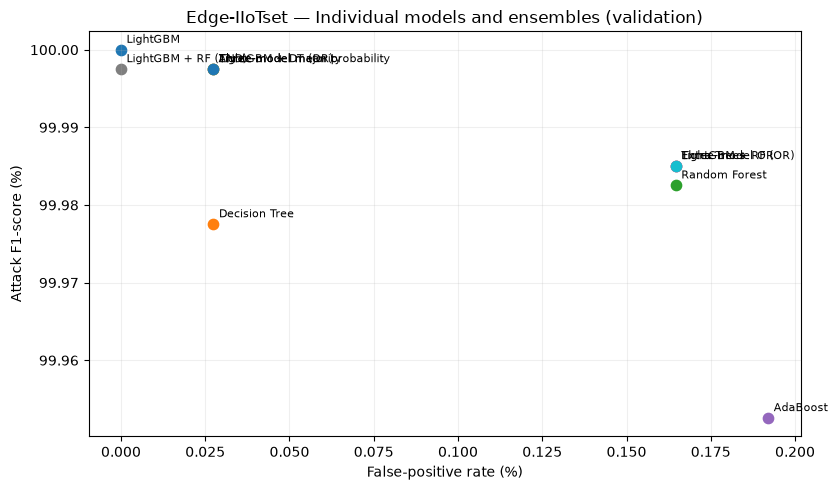

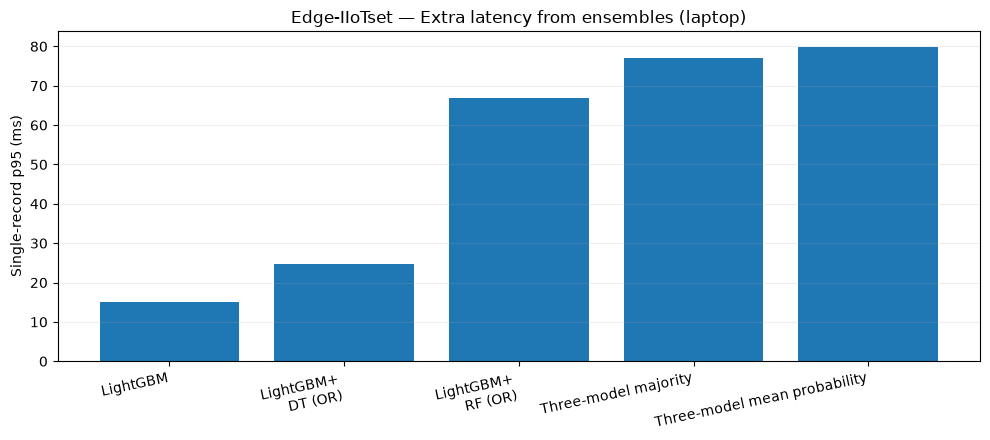

Saved 5 CSVs, 2 figures, 1 JSON. TEST NOT OPENED. No training.
Conclusion: No demonstrated F1 improvement over LightGBM in this validation split.


In [9]:
comparison.to_csv(METRICS/'edge_iiotset_v3_ensemble_comparison.csv',index=False)
diversity.to_csv(METRICS/'edge_iiotset_v3_model_error_diversity.csv',index=False)
categories.to_csv(METRICS/'edge_iiotset_v3_ensemble_attack_types.csv',index=False)
resources.to_csv(METRICS/'edge_iiotset_v3_ensemble_resources.csv',index=False)
port_summary.to_csv(METRICS/'edge_iiotset_v3_ensemble_port_warning.csv',index=False)

fig,ax=plt.subplots(figsize=(8.5,5))
for r in comparison.itertuples(index=False):
    ax.scatter(r.false_positive_pct,r.attack_f1_pct,s=55)
    ax.annotate(r.candidate,(r.false_positive_pct,r.attack_f1_pct),xytext=(4,5),
                textcoords='offset points',fontsize=8)
ax.set_xlabel('False-positive rate (%)');ax.set_ylabel('Attack F1-score (%)')
ax.set_title('Edge-IIoTset — Individual models and ensembles (validation)')
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(FIGURES/'edge_iiotset_v3_ensemble_tradeoff.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

fig,ax=plt.subplots(figsize=(10,4.5))
chosen=['LightGBM','LightGBM + DT (OR)','LightGBM + RF (OR)','Three-model majority','Three-model mean probability']
selected=resources.set_index('candidate').loc[chosen]
ax.bar(range(len(selected)),selected['single_record_p95_ms'].to_numpy())
ax.set_xticks(range(len(selected)),[n.replace(' + ','+\n') for n in chosen],rotation=12,ha='right')
ax.set_ylabel('Single-record p95 (ms)')
ax.set_title('Edge-IIoTset — Extra latency from ensembles (laptop)')
ax.grid(axis='y',alpha=.2);fig.tight_layout()
fig.savefig(FIGURES/'edge_iiotset_v3_ensemble_latency.png',dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

baseline=comparison.loc[comparison['candidate']=='LightGBM'].iloc[0]
ensemble=comparison[comparison['candidate'].str.contains(r'\+|Three-model',regex=True)]
any_gain=bool((ensemble['attack_f1_pct']>baseline['attack_f1_pct']+1e-9).any())
summary={
 'dataset':'Edge-IIoTset selected ML CSV','feature_set':'Core16',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'train_rows':expected['train'],'validation_rows':len(y),'test_scored':False,
 'frozen_manifest_sha256':manifest_hash,
 'models_verified':MODEL_NAMES,'candidate_count':len(variants),
 'baseline_lightgbm_f1_pct':round(float(baseline['attack_f1_pct']),6),
 'any_ensemble_improved_f1':any_gain,
 'noport_validation_overlap_rows':int(port_summary['noport_overlap_validation_rows'].iloc[0]),
 'attack_types_absent_from_validation':missing_types,
 'conclusion':'No demonstrated F1 improvement over LightGBM in this validation split.' if not any_gain else 'An ensemble improved validation F1; compare costs and split limitations.',
 'limitations':['Ports-only model almost perfectly predicts labels on this split; possible collection shortcut.',
     'Removing ports creates overlapping 14-feature fingerprints across train/validation.',
     'MITM is absent from validation and cannot be evaluated.',
     'Core16 grouping does not prove capture-session or independent-device generalization.',
     'All inference/resource numbers are laptop measurements.',
     'Attack labels are binary packet-level records, not proven multi-stage APT detections.']}
(AUDITS/'edge_iiotset_v3_ensemble_screening.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Saved 5 CSVs, 2 figures, 1 JSON. TEST NOT OPENED. No training.')
print('Conclusion:',summary['conclusion'])